# CSE558 Midterm Project — Did the Impact Player rule change the IPL?

**Dataset:** "IPL Ball-by-Ball 2008–2026: All 19 Seasons" (Kaggle, abirambharathisa), built from Cricsheet
(cricsheet.org) ball-by-ball records.

* `ipl_ball_by_ball_2008_2026.csv`: one row per delivery (295,732 × 38). Main table: size check, preparation.
* `ipl_matches_2008_2026.csv`: one row per match (1,243 × 32): toss, result, method, innings totals.

Sections: 1 Dataset and size check · 2 Preparation · 3 Before vs after · 4 EDA and problem statements ·
5 Five hypothesis tests · Limitations · 6 Export.

**Unit of analysis.** Balls within one innings are not independent (the same batters, bowlers, pitch and
match situation), so no test runs on balls. Tests run on **innings** (H1, H2, H5) or **matches** (H3, H4),
and each match contributes at most one observation per test.

In [1]:
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from matplotlib.patches import Patch
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

BALLS_PATH = Path(os.environ.get("IPL_BALLS", "ipl_ball_by_ball_2008_2026.csv"))
MATCHES_PATH = Path(os.environ.get("IPL_MATCHES", "ipl_matches_2008_2026.csv"))
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
RESULTS = {}
ALPHA = 0.05

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # validated categorical order: blue, orange, aqua, yellow
INK, INK2, GRID, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#a3a29c"
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "font.size": 8, "axes.titlesize": 8.5,
    "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.6,
    "legend.frameon": False, "savefig.bbox": "tight", "axes.axisbelow": True,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf"); fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

def era_of(season):
    return "Impact" if season >= 2023 else ("Pre" if season >= 2018 else "Early")

## 1. Dataset and size check

In [2]:
balls_raw = pd.read_csv(BALLS_PATH, low_memory=False)
matches_raw = pd.read_csv(MATCHES_PATH)
nb, pb = balls_raw.shape; nm, pm_ = matches_raw.shape
print(f"Balls: {nb:,} x {pb} = {nb * pb:,} cells | Matches: {nm:,} x {pm_}")
print("Seasons:", balls_raw["season"].min(), "to", balls_raw["season"].max(), "| matches per season:")
print(matches_raw.groupby("season").size().to_dict())
RESULTS["raw"] = {"balls_rows": nb, "balls_cols": pb, "balls_cells": nb * pb, "match_rows": nm, "match_cols": pm_,
                  "seasons": int(balls_raw["season"].nunique())}
balls_raw.head(3)

Balls: 295,732 x 38 = 11,237,816 cells | Matches: 1,243 x 32
Seasons: 2008 to 2026 | matches per season:
{2008: 58, 2009: 57, 2010: 60, 2011: 73, 2012: 74, 2013: 76, 2014: 60, 2015: 59, 2016: 60, 2017: 59, 2018: 60, 2019: 60, 2020: 60, 2021: 60, 2022: 74, 2023: 74, 2024: 71, 2025: 74, 2026: 74}


,match_id,season,date,venue,innings,is_super_over,batting_team,bowling_team,over,ball,delivery_in_over,phase,batter,non_striker,bowler,batter_runs,extra_runs,total_runs,extra_type,is_legal_ball,is_four,is_six,is_dot,is_wicket,player_out,dismissal_kind,fielders,bowler_wicket,team_score,team_wickets,legal_balls_bowled,current_run_rate,target,runs_needed,balls_left,required_run_rate,review_by,review_decision
0,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,1,1,Powerplay,SC Ganguly,BB McCullum,P Kumar,0,1,1,legbyes,True,False,False,False,False,NaN,NaN,NaN,False,1,0,1,6.0,NaN,NaN,NaN,NaN,NaN,NaN
1,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,2,2,Powerplay,BB McCullum,SC Ganguly,P Kumar,0,0,0,NaN,True,False,False,True,False,NaN,NaN,NaN,False,1,0,2,3.0,NaN,NaN,NaN,NaN,NaN,NaN
2,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,3,Powerplay,BB McCullum,SC Ganguly,P Kumar,0,1,1,wides,False,False,False,False,False,NaN,NaN,NaN,False,2,0,2,6.0,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data preparation

In [3]:
b = balls_raw.copy(); m = matches_raw.copy()
log = []

# 2.1 Duplicates: (match, innings, over, ball) repeats because wides/no-balls are re-bowled with the same ball number
dup_ballkey = int(b.duplicated(["match_id", "innings", "over", "ball"]).sum())
dup_delivery = int(b.duplicated(["match_id", "innings", "over", "delivery_in_over"]).sum())
dup_full = int(b.duplicated().sum())
illegal_in_dups = b[b.duplicated(["match_id", "innings", "over", "ball"], keep=False)]["is_legal_ball"].eq(False).sum()
print(f"Repeated (match, innings, over, ball): {dup_ballkey:,}; on delivery_in_over: {dup_delivery}; full-row duplicates: {dup_full}")
log.append(("Repeated (match, innings, over, ball) keys", dup_ballkey,
            "kept; key changed to delivery_in_over (0 repeats)",
            "wides and no-balls are re-bowled with the same ball number; they are real deliveries, not duplicates"))

# 2.2 Super-over balls are not part of the 20-over contest
so = b["is_super_over"].astype(bool) | (b["innings"] > 2)
n_so = int(so.sum()); b = b.loc[~so].copy()
log.append(("Super-over balls (innings 3–6)", n_so, "removed",
            "a tie-breaker, not part of either team's 20 overs; would inflate totals"))

# 2.3 Structural missing values (not data loss)
miss = (balls_raw.isna().mean() * 100).round(1)
print(miss[miss > 0].to_dict())
for c in ["extra_type", "player_out", "dismissal_kind", "fielders"]:
    b[c] = b[c].fillna("none")
log.append(("extra_type / dismissal fields empty on 94–96% of balls", int(balls_raw["extra_type"].isna().sum()),
            "filled with 'none'", "empty means 'no extra' or 'no wicket', not unknown"))
log.append(("Chase fields (target, runs_needed, RRR) empty on 52%", int(balls_raw["target"].isna().sum()),
            "left empty; flagged as first innings", "there is no target in a first innings; imputing would invent one"))
n_review = int(balls_raw["review_by"].notna().sum())
b = b.drop(columns=["review_by", "review_decision"])
log.append(("review_by / review_decision 99.7% empty (DRS only from 2018)", nb - n_review,
            "columns dropped", "too sparse and absent before 2018"))
b["current_run_rate"] = b["current_run_rate"].fillna(0.0)
log.append(("current_run_rate empty when an over starts with a wide (0 legal balls)", int(balls_raw["current_run_rate"].isna().sum()),
            "set to 0", "run rate is undefined at 0 legal balls; 0 is the convention"))

# 2.4 Validity checks
inn_tot = b.groupby(["match_id", "innings"])["total_runs"].sum().unstack()
chk = m.set_index("match_id")[["first_innings_runs", "second_innings_runs"]].join(inn_tot)
mismatch = int((chk["first_innings_runs"] != chk[1]).sum() + ((chk["second_innings_runs"] != chk[2]) & chk[2].notna()).sum())
six_mismatch = int(((b["batter_runs"] == 6) & ~b["is_six"].astype(bool)).sum())
retired = int((b["dismissal_kind"] == "retired hurt").sum())
date_season = int((pd.to_datetime(m["date"]).dt.year != m["season"]).sum())
print("Innings total mismatches (balls vs match file):", mismatch, "| 6 runs without is_six:", six_mismatch,
      "| retired hurt:", retired, "| date/season mismatches:", date_season)
log.append(("Validity: innings totals in ball file vs match file", mismatch, "checked (all agree)", "confirms the two tables are consistent"))
log.append(("6 runs credited but not a six (all-run or overthrow)", six_mismatch, "use the is_six flag, not runs = 6",
            "counting them would overstate sixes"))
log.append(("'Retired hurt' marked as wicket", retired, "not counted as a wicket", "the batter was not dismissed"))

# 2.5 Team names: franchises renamed over time (already merged in this release; verified)
print(sorted(b["batting_team"].unique()))
log.append(("Franchise renames (Delhi Daredevils→Capitals, Kings XI→Punjab Kings, RCB Bangalore→Bengaluru)", 15,
            "verified one name per franchise (15 teams)", "otherwise one team's history splits in two"))

# 2.6 Matches unfit for score tests
m["era"] = m["season"].map(era_of)
no_result = m["result"].eq("No result"); tie = m["result"].eq("Tie (super over)")
dl = m["method"].eq("D/L"); reduced = m["target_overs"].lt(20) & ~dl
inc_first = (m["first_innings_overs"] < 20) & (m["first_innings_wickets"] < 10)
print(f"No result: {no_result.sum()}, ties: {tie.sum()}, D/L: {dl.sum()}, reduced overs (no D/L): {reduced.sum()}, "
      f"curtailed first innings: {inc_first.sum()}")
clean = m[~(no_result | tie | dl | reduced | inc_first)].copy()
log.append(("No result / tie / D/L / reduced-overs / curtailed matches",
            f"{no_result.sum()} / {tie.sum()} / {dl.sum()} / {reduced.sum()} / {int((inc_first & ~(no_result | dl | reduced)).sum())}",
            "left out of score and chase tests", "a shortened game is not a like-for-like 20-over contest"))
print("Clean full-length matches:", len(clean), "of", len(m))

# 2.7 Outliers: kept
fi = clean["first_innings_runs"]
q1, q3 = fi.quantile([.25, .75]); iqr = q3 - q1
n_out = int(((fi > q3 + 1.5 * iqr) | (fi < q1 - 1.5 * iqr)).sum())
log.append(("First-innings totals beyond the IQR fences", n_out, "kept", "record totals (e.g. 287) are real and are the effect H1 looks for"))
print("Totals beyond IQR fences (kept):", n_out, "| max:", int(fi.max()), "| min:", int(fi.min()))

Repeated (match, innings, over, ball): 11,075; on delivery_in_over: 0; full-row duplicates: 0


{'extra_type': 94.5, 'player_out': 95.0, 'dismissal_kind': 95.0, 'fielders': 96.4, 'current_run_rate': 0.1, 'target': 51.9, 'runs_needed': 51.9, 'balls_left': 51.9, 'required_run_rate': 52.0, 'review_by': 99.7, 'review_decision': 99.7}
Innings total mismatches (balls vs match file): 0 | 6 runs without is_six: 8 | retired hurt: 19 | date/season mismatches: 0
['Chennai Super Kings', 'Deccan Chargers', 'Delhi Capitals', 'Gujarat Lions', 'Gujarat Titans', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']
No result: 9, ties: 16, D/L: 23, reduced overs (no D/L): 11, curtailed first innings: 28
Clean full-length matches: 1183 of 1243
Totals beyond IQR fences (kept): 25 | max: 287 | min: 67


In [4]:
# 2.8 Encoding (ball table): booleans -> 0/1, nominal -> one-hot, IDs/names dropped from the model matrix
enc = b.copy()
bool_cols = [c for c in enc.columns if enc[c].dtype == bool]
enc[bool_cols] = enc[bool_cols].astype(int)
enc["chase_flag"] = (enc["innings"] == 2).astype(int)
enc["date"] = pd.to_datetime(enc["date"]); enc["month"] = enc["date"].dt.month; enc["weekday"] = enc["date"].dt.weekday
enc["era_impact"] = (enc["season"] >= 2023).astype(int)
enc["extra_type"] = enc["extra_type"].str.split(",").str[0].str.strip()
onehot = ["batting_team", "bowling_team", "phase", "extra_type", "dismissal_kind", "venue"]
enc = pd.get_dummies(enc, columns=onehot, dtype=int)
enc = enc.drop(columns=["date", "batter", "non_striker", "bowler", "player_out", "fielders", "is_super_over"])
ne, pe = enc.shape
print(f"Encoded: {ne:,} x {pe} = {ne * pe:,} cells (>= 3M: {ne * pe >= 3_000_000})")
RESULTS["encoded"] = {"rows": ne, "cols": pe, "cells": ne * pe}
prep_table = pd.DataFrame(log, columns=["Issue", "Count", "Action", "Why"])
prep_table

Encoded: 295,557 x 114 = 33,693,498 cells (>= 3M: True)


,Issue,Count,Action,Why
0,"Repeated (match, innings, over, ball) keys",11075,kept; key changed to delivery_in_over (0 repeats),wides and no-balls are re-bowled with the same...
1,Super-over balls (innings 3–6),175,removed,"a tie-breaker, not part of either team's 20 ov..."
2,extra_type / dismissal fields empty on 94–96% ...,279505,filled with 'none',"empty means 'no extra' or 'no wicket', not unk..."
3,"Chase fields (target, runs_needed, RRR) empty ...",153429,left empty; flagged as first innings,there is no target in a first innings; imputin...
4,review_by / review_decision 99.7% empty (DRS o...,294742,columns dropped,too sparse and absent before 2018
5,current_run_rate empty when an over starts wit...,165,set to 0,run rate is undefined at 0 legal balls; 0 is t...
6,Validity: innings totals in ball file vs match...,0,checked (all agree),confirms the two tables are consistent
7,6 runs credited but not a six (all-run or over...,8,"use the is_six flag, not runs = 6",counting them would overstate sixes
8,'Retired hurt' marked as wicket,19,not counted as a wicket,the batter was not dismissed
9,"Franchise renames (Delhi Daredevils→Capitals, ...",15,verified one name per franchise (15 teams),otherwise one team's history splits in two


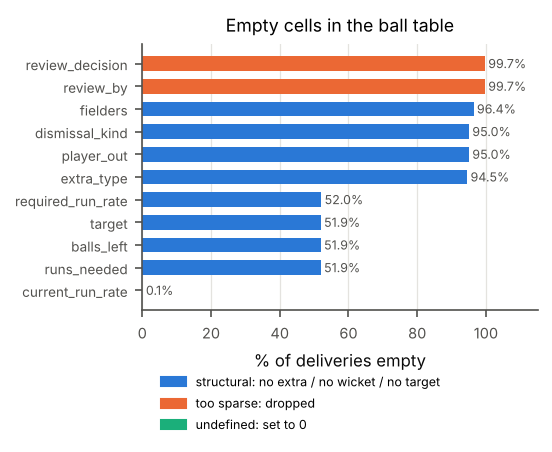

In [5]:
# Figure 0: where the empty cells are, and what they mean
mp = (balls_raw.isna().mean() * 100).sort_values()
mp = mp[mp > 0]
kind = {"extra_type": "structural", "player_out": "structural", "dismissal_kind": "structural", "fielders": "structural",
        "target": "structural", "runs_needed": "structural", "balls_left": "structural", "required_run_rate": "structural",
        "review_by": "dropped", "review_decision": "dropped", "current_run_rate": "fixed"}
colmap = {"structural": SERIES[0], "dropped": SERIES[1], "fixed": SERIES[2]}
fig, ax = plt.subplots(figsize=(3.4, 2.3))
ax.barh(range(len(mp)), mp.values, color=[colmap[kind[c]] for c in mp.index], height=0.65)
ax.set_yticks(range(len(mp))); ax.set_yticklabels(mp.index, fontsize=6.5); ax.grid(axis="y", visible=False)
for i, v in enumerate(mp.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=6, color=INK2)
ax.set_xlim(0, 115); ax.set_xlabel("% of deliveries empty")
ax.legend(handles=[Patch(color=colmap[k], label=l) for k, l in
                   [("structural", "structural: no extra / no wicket / no target"), ("dropped", "too sparse: dropped"), ("fixed", "undefined: set to 0")]],
          loc="upper center", bbox_to_anchor=(0.4, -0.2), fontsize=6, ncol=1)
ax.set_title("Empty cells in the ball table")
save(fig, "fig0_missing")

## 3. Before vs after preparation

In [6]:
before_after = pd.DataFrame({
    "Before": [f"{nb:,}", pb, f"{dup_ballkey:,}", n_so, f"{int(balls_raw['extra_type'].isna().sum()):,}", 2, f"{nm:,}", "—"],
    "After": [f"{ne:,}", pe, "0 (key: delivery_in_over)", 0, "0 ('none')", 0, f"{nm:,}", f"{len(clean):,}"],
}, index=["Ball rows", "Ball attributes", "Repeated ball keys", "Super-over balls", "Empty extra_type",
          "Review columns", "Matches", "Clean full-length matches (score/chase tests)"])
RESULTS["before_after"] = before_after.astype(str).to_dict()
RESULTS["prep"] = {"dup_ballkey": dup_ballkey, "super_over_balls": n_so, "no_result": int(no_result.sum()), "ties": int(tie.sum()),
                   "dl": int(dl.sum()), "reduced": int(reduced.sum()), "curtailed_first": int(inc_first.sum()),
                   "clean_matches": int(len(clean)), "six_mismatch": six_mismatch, "retired_hurt": retired, "iqr_outliers": n_out,
                   "max_total": int(fi.max()), "min_total": int(fi.min())}
before_after

,Before,After
Ball rows,"295,732","295,557"
Ball attributes,38,114
Repeated ball keys,"11,075",0 (key: delivery_in_over)
Super-over balls,175,0
Empty extra_type,"279,505",0 ('none')
Review columns,2,0
Matches,"1,243","1,243"
Clean full-length matches (score/chase tests),—,"1,183"


### Box plots: what preparation removed, and why the outliers stay
(a) First-innings totals from all 1,243 matches vs the 1,183 full-length matches: the low tail (down to 25 runs) comes from
rain-shortened and D/L games, which is why they leave the score tests. (b) The clean totals by era with the IQR fences
of the pooled data: the outliers left are real record totals, and they cluster in the Impact era, which is the effect H1 tests.

{'fences': [86.75, 252.75], 'outliers_by_era': {'Early': {'low': 7, 'high': 1, 'n': 601}, 'Impact': {'low': 1, 'high': 13, 'n': 279}, 'Pre': {'low': 3, 'high': 0, 'n': 303}}, 'excluded_median': 150.0, 'excluded_min': 25.0, 'all_min': 25.0, 'clean_min': 67.0, 'clean_median': 168.0, 'all_median': 168.0}


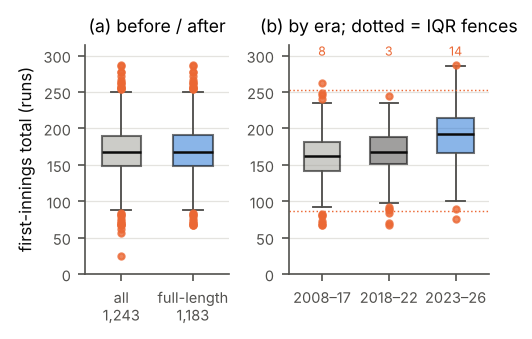

In [7]:
allfi = m["first_innings_runs"].dropna()
q1b, q3b = fi.quantile([.25, .75]); iqrb = q3b - q1b; lo_f, hi_f = q1b - 1.5 * iqrb, q3b + 1.5 * iqrb
clean_era = clean.assign(era=clean["season"].map(era_of))
out_by_era = {e: {"low": int((g["first_innings_runs"] < lo_f).sum()), "high": int((g["first_innings_runs"] > hi_f).sum()), "n": len(g)}
              for e, g in clean_era.groupby("era")}
excluded = m[~m["match_id"].isin(clean["match_id"])]["first_innings_runs"].dropna()
RESULTS["box"] = {"fences": [round(float(lo_f), 2), round(float(hi_f), 2)], "outliers_by_era": out_by_era,
                  "excluded_median": float(excluded.median()), "excluded_min": float(excluded.min()),
                  "all_min": float(allfi.min()), "clean_min": float(fi.min()), "clean_median": float(fi.median()), "all_median": float(allfi.median())}
print(RESULTS["box"])
bp_kw = dict(widths=0.55, patch_artist=True, medianprops=dict(color=INK, lw=1.2),
             whiskerprops=dict(color=INK2, lw=0.9), capprops=dict(color=INK2, lw=0.9),
             flierprops=dict(marker="o", ms=3, mfc=SERIES[1], mec=SERIES[1], alpha=0.8))
fig, axes = plt.subplots(1, 2, figsize=(3.4, 2.3), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
b1 = ax.boxplot([allfi.values, fi.values], **bp_kw)
for patch, c in zip(b1["boxes"], [MUTED, SERIES[0]]): patch.set_facecolor(c); patch.set_alpha(0.55)
ax.set_xticks([1, 2]); ax.set_xticklabels(["all\n1,243", "full-length\n1,183"]); ax.grid(axis="x", visible=False)
ax.set_ylabel("first-innings total (runs)"); ax.set_title("(a) before / after")
ax = axes[1]
data_e = [clean_era[clean_era["era"] == e]["first_innings_runs"].values for e in ["Early", "Pre", "Impact"]]
b2 = ax.boxplot(data_e, **bp_kw)
for patch, c in zip(b2["boxes"], [MUTED, INK2, SERIES[0]]): patch.set_facecolor(c); patch.set_alpha(0.55)
for yv in (lo_f, hi_f): ax.axhline(yv, color=SERIES[1], lw=0.7, ls=":")
for i, e in enumerate(["Early", "Pre", "Impact"], start=1):
    ax.text(i, 300, f"{out_by_era[e]['low'] + out_by_era[e]['high']}", ha="center", fontsize=6, color=SERIES[1])
ax.set_ylim(0, 315); axes[0].set_ylim(0, 315)
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["2008–17", "2018–22", "2023–26"]); ax.grid(axis="x", visible=False)
ax.set_title("(b) by era; dotted = IQR fences")
fig.tight_layout()
save(fig, "fig_box_prep")

## 4. Innings table, EDA and problem statements

In [8]:
b["wkt"] = b["is_wicket"].astype(bool) & (b["dismissal_kind"] != "retired hurt")
b["pp_wkt"] = b["wkt"] & b["phase"].eq("Powerplay")
b["death_run"] = b["total_runs"].where(b["phase"].eq("Death"), 0)
inn = (b.groupby(["match_id", "innings"])
         .agg(runs=("total_runs", "sum"), sixes=("is_six", "sum"), fours=("is_four", "sum"),
              wkts=("wkt", "sum"), legal=("is_legal_ball", "sum"), pp_wkts=("pp_wkt", "sum"),
              death_runs=("death_run", "sum"))
         .reset_index())
inn = inn.merge(m[["match_id", "season", "era", "country", "batting_first", "winner", "toss_winner", "toss_decision"]], on="match_id")
first = inn[(inn["innings"] == 1) & inn["match_id"].isin(clean["match_id"])].copy()
first["bf_won"] = (first["winner"] == first["batting_first"]).astype(int)
first = first.merge(m[["match_id", "venue"]], on="match_id")
first["impact"] = (first["season"] >= 2023).astype(int); first["t"] = first["season"] - 2008
first["rate120"] = first["sixes"] / first["legal"] * 120
print("Clean first innings:", len(first)); first.groupby("era")[["runs", "sixes"]].mean().round(2)

Clean first innings: 1183


,runs,sixes
era,,
Early,161.00,5.42
Impact,190.40,9.28
Pre,168.12,6.99


**Basic questions**
1. Which franchise has won the most matches? 2. Do captains prefer to field after winning the toss?
3. Are totals rising over the seasons?

In [9]:
wins = m["winner"].value_counts()
field_share = (m["toss_decision"] == "field").mean()
field_by_era = m.groupby("era")["toss_decision"].apply(lambda s: (s == "field").mean()).round(3).to_dict()
season_tot = first.groupby("season")["runs"].mean()
rho, p_rho = stats.spearmanr(season_tot.index, season_tot.values)
RESULTS["basic"] = {"most_wins_team": wins.index[0], "most_wins": int(wins.iloc[0]), "field_share": round(float(field_share), 3),
                    "field_share_by_era": field_by_era, "spearman_season_total": round(float(rho), 2), "p_spearman": float(p_rho),
                    "mean_total_2008": round(float(season_tot.loc[2008]), 1), "mean_total_2026": round(float(season_tot.loc[2026]), 1)}
print(RESULTS["basic"])

{'most_wins_team': 'Mumbai Indians', 'most_wins': 157, 'field_share': 0.664, 'field_share_by_era': {'Early': 0.571, 'Impact': 0.771, 'Pre': 0.752}, 'spearman_season_total': 0.84, 'p_spearman': 7.293998331953698e-06, 'mean_total_2008': 163.2, 'mean_total_2026': 196.4}


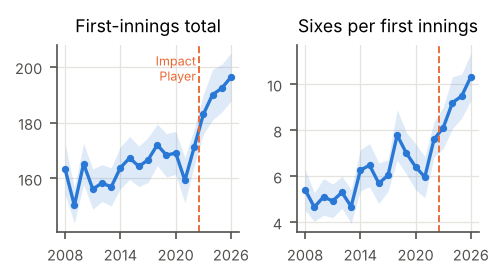

In [10]:
# Figure 1: season averages of first-innings total and sixes (two panels; different scales, no dual axis)
g = first.groupby("season").agg(runs=("runs", "mean"), runs_se=("runs", lambda x: x.std(ddof=1) / np.sqrt(len(x))),
                                 sixes=("sixes", "mean"), sixes_se=("sixes", lambda x: x.std(ddof=1) / np.sqrt(len(x))))
fig, axes = plt.subplots(1, 2, figsize=(3.4, 1.9), sharex=True)
for ax, col, title in zip(axes, ["runs", "sixes"], ["First-innings total", "Sixes per first innings"]):
    ax.fill_between(g.index, g[col] - 1.96 * g[f"{col}_se"], g[col] + 1.96 * g[f"{col}_se"], color=SERIES[0], alpha=0.15, lw=0)
    ax.plot(g.index, g[col], color=SERIES[0], marker="o", ms=2.5)
    ax.axvline(2022.5, color=SERIES[1], lw=0.9, ls="--")
    ax.set_title(title); ax.set_xticks([2008, 2014, 2020, 2026])
axes[0].text(2022.2, axes[0].get_ylim()[1] * 0.985, "Impact\nPlayer", fontsize=6, color=SERIES[1], ha="right", va="top")
fig.tight_layout()
save(fig, "fig1_seasons")

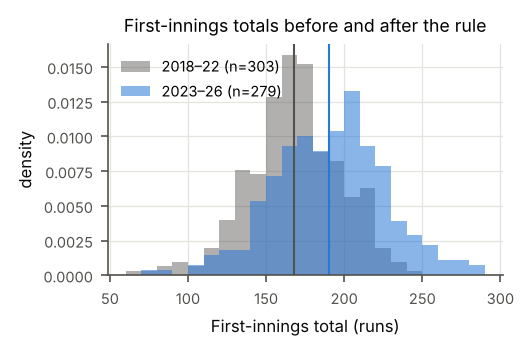

In [11]:
# Figure 2: distribution of first-innings totals, pre-rule vs Impact era
pre = first[first["era"] == "Pre"]; imp = first[first["era"] == "Impact"]
fig, ax = plt.subplots(figsize=(3.4, 2.0))
bins = np.arange(60, 300, 10)
ax.hist(pre["runs"], bins=bins, color=INK2, alpha=0.45, label=f"2018–22 (n={len(pre)})", density=True)
ax.hist(imp["runs"], bins=bins, color=SERIES[0], alpha=0.55, label=f"2023–26 (n={len(imp)})", density=True)
ax.axvline(pre["runs"].mean(), color=INK2, lw=1); ax.axvline(imp["runs"].mean(), color=SERIES[0], lw=1)
ax.set_xlabel("First-innings total (runs)"); ax.set_ylabel("density"); ax.legend(loc="upper left")
ax.set_title("First-innings totals before and after the rule")
save(fig, "fig2_totals")

### Problem statements
* **P1 (primary).** Did the Impact Player rule (2023 onward) raise scoring? (H1 totals, H2 sixes)
* **P2.** Do the toss and the choice to chase decide IPL matches, and has the chase edge changed across eras? (H3, H4)
* **P3.** How decisive is an early collapse: does losing 3+ wickets in the powerplay sink the batting-first team? (H5)

**Novel:** the basic questions count wins and totals per team. Ours treat a rule change as a natural experiment
(before vs after, same league) and turn ball-level events into innings-level outcomes no single row records.

## 5. Hypothesis tests

Eras: **Pre** = 2018–2022, **Impact** = 2023–2026, **Early** = 2008–2017. Tests H1, H2, H4, H5 use clean full-length
matches; H3 uses every match with a result.

In [12]:
def hl_two_sample(x, y, conf=0.95):
    """Hodges–Lehmann shift (median of all x - y) with the Mann–Whitney-based CI."""
    x = np.asarray(x); y = np.asarray(y); n1, n2 = len(x), len(y)
    d = np.sort((x[:, None] - y[None, :]).ravel())
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    k = int(np.floor(n1 * n2 / 2 - z * np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)))
    return float(np.median(d)), float(d[k]), float(d[len(d) - k - 1])

def two_prop(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2; pool = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(pool * (1 - pool) * (1 / n1 + 1 / n2))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return p1, p2, z, (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se)

### Why each test, and how the tests link up
The primary tests are the standard ones from the course: two-sample t (H1 and H2),
one-proportion z (H3), chi-square test of independence (H4) and two-proportion z (H5). The choice follows
the response type (continuous, count, binary) and the number of groups. Several of them are the same test in another form,
which the cell after H5 checks numerically: with two groups, one-way ANOVA's F equals the pooled t squared; a two-proportion
z squared equals the 2×2 chi-square; the one-proportion z squared equals the chi-square goodness-of-fit statistic.

### H1: Are first-innings totals higher in the Impact era?
H0: μ_Impact − μ_Pre ≤ 0; H1: > 0. α = 0.05, one-sided. **Welch t-test.** Smallest difference that matters: **10 runs**
(about one extra boundary-over; less than that would not change a par score).

In [13]:
x, y = imp["runs"].values, pre["runs"].values
w1 = stats.ttest_ind(x, y, equal_var=False, alternative="greater")
ci1 = stats.ttest_ind(x, y, equal_var=False).confidence_interval(0.95)
lev = stats.levene(x, y)
pooled = stats.ttest_ind(x, y, equal_var=True, alternative="greater")
mw1 = stats.mannwhitneyu(x, y, alternative="greater")
hl1 = hl_two_sample(x, y)
perm = stats.permutation_test((x, y), lambda a, c: np.mean(a) - np.mean(c), n_resamples=20000,
                              alternative="greater", random_state=558)
sd_p = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
# Sensitivity: India-only matches (drops 2020 and part of 2021 played in the UAE)
xi = imp[imp["country"] == "India"]["runs"]; yi = pre[pre["country"] == "India"]["runs"]
w1i = stats.ttest_ind(xi, yi, equal_var=False, alternative="greater")
ci1i = stats.ttest_ind(xi, yi, equal_var=False).confidence_interval(0.95)
RESULTS["H1"] = {
    "n_impact": len(x), "n_pre": len(y), "mean_impact": round(x.mean(), 1), "mean_pre": round(y.mean(), 1),
    "sd_impact": round(x.std(ddof=1), 1), "sd_pre": round(y.std(ddof=1), 1),
    "diff": round(x.mean() - y.mean(), 1), "CI": [round(float(ci1.low), 1), round(float(ci1.high), 1)],
    "t": round(float(w1.statistic), 2), "df": round(float(w1.df), 1), "p": float(w1.pvalue),
    "cohens_d": round((x.mean() - y.mean()) / sd_p, 2),
    "levene_W": round(float(lev.statistic), 2), "levene_p": float(lev.pvalue),
    "pooled_t": round(float(pooled.statistic), 2), "pooled_df": int(len(x) + len(y) - 2), "pooled_p": float(pooled.pvalue),
    "MW_U": float(mw1.statistic), "MW_p": float(mw1.pvalue), "HL": round(hl1[0], 1), "HL_CI": [round(hl1[1], 1), round(hl1[2], 1)],
    "perm_p": float(perm.pvalue),
    "india_n": [int(len(xi)), int(len(yi))], "india_diff": round(float(xi.mean() - yi.mean()), 1),
    "india_CI": [round(float(ci1i.low), 1), round(float(ci1i.high), 1)], "india_p": float(w1i.pvalue),
    "skew_impact": round(float(stats.skew(x)), 2), "skew_pre": round(float(stats.skew(y)), 2),
}
for k, v in RESULTS["H1"].items(): print(f"{k:>14}: {v}")

      n_impact: 279
         n_pre: 303
   mean_impact: 190.4
      mean_pre: 168.1
     sd_impact: 35.7
        sd_pre: 29.9
          diff: 22.3
            CI: [16.9, 27.7]
             t: 8.13
            df: 544.0
             p: 1.5119127798886912e-15
      cohens_d: 0.68
      levene_W: 9.77
      levene_p: 0.0018605633847677823
      pooled_t: 8.18
     pooled_df: 580
      pooled_p: 8.722277088155419e-16
          MW_U: 57964.5
          MW_p: 4.770848331440309e-15
            HL: 22.0
         HL_CI: [17.0, 28.0]
        perm_p: 4.999750012499375e-05
       india_n: [279, 216]
    india_diff: 20.1
      india_CI: [14.3, 25.8]
       india_p: 1.1303357120393414e-11
   skew_impact: -0.08
      skew_pre: -0.29


**b) Other tests.** Two independent groups of innings, a continuous response, unknown σ → two-sample t. Welch, because
Levene rejects equal variances (W = 9.77, p = 0.002). Pooled t (assumes equal σ): same decision. Mann–Whitney and a
permutation test (no distribution assumption): same decision; HL shift +22 (17 to 28). z-test: needs σ. Paired t: no pairing.

**c) Result.** Impact-era first innings average **190.4 vs 168.1**: **+22.3 runs** (95% CI 16.9 to 27.7; t = 8.13,
544 d.f., p ≈ 1.5×10⁻¹⁵, Cohen's d = 0.68). Reject H0; the whole CI clears 10 runs, so it **matters**. India-only matches:
+20.1 (14.3 to 25.8), so the UAE seasons do not drive it. Caveat: totals were already rising before 2023 (Fig. 1).

**H1, deeper: is the jump more than the trend?** Totals were already rising before 2023 (Fig. 1). We fit
`runs ~ season trend + Impact` on all 19 seasons (HC3 robust SE), the same with standard errors clustered by season, and
with venue fixed effects (same ground before and after). Placebo test: pretend the rule began in each year 2011–2021 and fit
the same model on 2008–22 only; a real effect should be far larger than any placebo jump.

In [14]:
f1 = smf.ols("runs ~ t + impact", first).fit(cov_type="HC3")
f1c = smf.ols("runs ~ t + impact", first).fit(cov_type="cluster", cov_kwds={"groups": first["season"]})
f1v = smf.ols("runs ~ t + impact + C(venue)", first).fit(cov_type="HC3")
pre_all = first[first["season"] <= 2022].copy(); placebo = {}
for yr in range(2011, 2022):
    pre_all["fake"] = (pre_all["season"] >= yr).astype(int)
    r = smf.ols("runs ~ t + fake", pre_all).fit(cov_type="HC3")
    placebo[yr] = {"jump": round(float(r.params["fake"]), 1), "lo": round(float(r.conf_int().loc["fake", 0]), 1),
                   "hi": round(float(r.conf_int().loc["fake", 1]), 1), "p": float(r.pvalues["fake"])}
trend_pre = smf.ols("runs ~ t", pre_all).fit()
obs_imp = first[first["impact"] == 1].groupby("season")["runs"].mean()
pred_imp = trend_pre.predict(pd.DataFrame({"t": obs_imp.index - 2008}))
RESULTS["H1"]["trend_jump"] = round(float(f1.params["impact"]), 1)
RESULTS["H1"]["trend_jump_CI"] = [round(float(v), 1) for v in f1.conf_int().loc["impact"]]
RESULTS["H1"]["trend_jump_p"] = float(f1.pvalues["impact"])
RESULTS["H1"]["trend_slope"] = round(float(f1.params["t"]), 2)
RESULTS["H1"]["cluster_CI"] = [round(float(v), 1) for v in f1c.conf_int().loc["impact"]]
RESULTS["H1"]["cluster_p"] = float(f1c.pvalues["impact"])
RESULTS["H1"]["venueFE_jump"] = round(float(f1v.params["impact"]), 1)
RESULTS["H1"]["venueFE_CI"] = [round(float(v), 1) for v in f1v.conf_int().loc["impact"]]
RESULTS["H1"]["venueFE_p"] = float(f1v.pvalues["impact"])
RESULTS["H1"]["placebo"] = placebo
RESULTS["H1"]["placebo_max_abs"] = max(abs(v["jump"]) for v in placebo.values())
RESULTS["H1"]["trend_forecast"] = {int(k): round(float(v), 1) for k, v in zip(obs_imp.index, pred_imp)}
RESULTS["H1"]["observed_impact_means"] = {int(k): round(float(v), 1) for k, v in obs_imp.items()}
print({k: RESULTS["H1"][k] for k in ["trend_jump", "trend_jump_CI", "cluster_CI", "venueFE_jump", "venueFE_CI", "placebo_max_abs"]})

{'trend_jump': 18.1, 'trend_jump_CI': [11.9, 24.3], 'cluster_CI': [10.6, 25.6], 'venueFE_jump': 19.5, 'venueFE_CI': [12.0, 27.0], 'placebo_max_abs': 7.7}


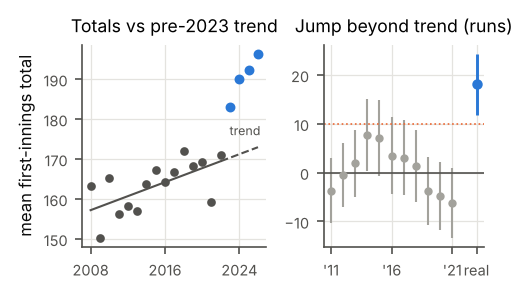

In [15]:
# Figure 5: (left) observed season means vs the pre-2023 trend projected forward; (right) placebo jumps vs the real one
fig, axes = plt.subplots(1, 2, figsize=(3.4, 2.0), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
gm = first.groupby("season")["runs"].mean()
tt_ = np.arange(0, 19)
ax.plot(2008 + tt_[:15], trend_pre.predict(pd.DataFrame({"t": tt_[:15]})), color=INK2, lw=1)
ax.plot(2008 + tt_[14:], trend_pre.predict(pd.DataFrame({"t": tt_[14:]})), color=INK2, lw=1, ls="--")
ax.scatter(gm.index[gm.index <= 2022], gm[gm.index <= 2022], color=INK2, s=10, zorder=3)
ax.scatter(gm.index[gm.index >= 2023], gm[gm.index >= 2023], color=SERIES[0], s=14, zorder=3)
ax.set_title("Totals vs pre-2023 trend"); ax.set_xticks([2008, 2016, 2024]); ax.set_ylabel("mean first-innings total")
ax.text(2024.6, 176, "trend", fontsize=6, color=INK2, ha="center")
ax = axes[1]
yrs = list(placebo.keys())
ax.errorbar(yrs, [placebo[y]["jump"] for y in yrs], yerr=[[placebo[y]["jump"] - placebo[y]["lo"] for y in yrs],
            [placebo[y]["hi"] - placebo[y]["jump"] for y in yrs]], fmt="o", ms=3, color=MUTED, lw=1, capsize=0)
ax.errorbar([2023], [f1.params["impact"]], yerr=[[f1.params["impact"] - f1.conf_int().loc["impact", 0]],
            [f1.conf_int().loc["impact", 1] - f1.params["impact"]]], fmt="o", ms=4, color=SERIES[0], lw=1.4, capsize=0)
ax.axhline(0, color=INK2, lw=0.8); ax.axhline(10, color=SERIES[1], lw=0.8, ls=":")
ax.set_title("Jump beyond trend (runs)"); ax.set_xticks([2011, 2016, 2021, 2023]); ax.set_xticklabels(["'11", "'16", "'21", "real"])
fig.tight_layout()
save(fig, "fig5_h1_trend")

**Reading.** Net of a 0.94 run-per-season trend, the Impact era adds **+18.1 runs** (11.9 to 24.3); clustered by season
10.6 to 25.6; with venue fixed effects +19.5 (12.0 to 27.0). Every lower bound clears 10 runs. No placebo year comes close:
the largest fake jump is 7.7 runs (2014, the season that began in the UAE). The pre-2023 trend predicts 170–173 for
2023–26; observed means are 183–196.

### H2: Do teams hit more sixes per innings in the Impact era?
H0: μ_Impact − μ_Pre ≤ 0 (mean sixes per first innings); H1: > 0. α = 0.05, one-sided. **Welch t-test**.
Smallest difference that matters: **1 six per innings**.

In [16]:
x2, y2 = imp["sixes"].values, pre["sixes"].values
mw2 = stats.mannwhitneyu(x2, y2, alternative="greater")
hl2 = hl_two_sample(x2, y2)
rbc = 2 * mw2.statistic / (len(x2) * len(y2)) - 1                   # rank-biserial correlation
w2 = stats.ttest_ind(x2, y2, equal_var=False, alternative="greater")
ci2 = stats.ttest_ind(x2, y2, equal_var=False).confidence_interval(0.95)
disp = {e: round(float(v.var(ddof=1) / v.mean()), 2) for e, v in [("Impact", x2), ("Pre", y2)]}
pois = stats.poisson_means_test(int(x2.sum()), len(x2), int(y2.sum()), len(y2), alternative="greater")
lev2 = stats.levene(x2, y2)
pooled2 = stats.ttest_ind(x2, y2, equal_var=True, alternative="greater")
sd2 = np.sqrt(((len(x2) - 1) * x2.var(ddof=1) + (len(y2) - 1) * y2.var(ddof=1)) / (len(x2) + len(y2) - 2))
RESULTS["H2"] = {
    "n_impact": len(x2), "n_pre": len(y2), "mean_impact": round(x2.mean(), 2), "mean_pre": round(y2.mean(), 2),
    "sd_impact": round(float(x2.std(ddof=1)), 2), "sd_pre": round(float(y2.std(ddof=1)), 2),
    "median_impact": float(np.median(x2)), "median_pre": float(np.median(y2)),
    "p": float(w2.pvalue), "cohens_d": round(float((x2.mean() - y2.mean()) / sd2), 2),
    "skew_impact": round(float(stats.skew(x2)), 2), "skew_pre": round(float(stats.skew(y2)), 2),
    "levene_W": round(float(lev2.statistic), 2), "levene_p": float(lev2.pvalue),
    "pooled_t": round(float(pooled2.statistic), 2), "pooled_p": float(pooled2.pvalue),
    "U": float(mw2.statistic), "MW_p": float(mw2.pvalue), "MW_z": round(float(stats.norm.isf(mw2.pvalue)), 2),
    "HL": round(hl2[0], 1), "HL_CI": [round(hl2[1], 1), round(hl2[2], 1)], "rank_biserial": round(float(rbc), 2),
    "welch_t": round(float(w2.statistic), 2), "welch_df": round(float(w2.df), 1), "welch_p": float(w2.pvalue),
    "mean_diff": round(float(x2.mean() - y2.mean()), 2), "mean_diff_CI": [round(float(ci2.low), 2), round(float(ci2.high), 2)],
    "dispersion_var_over_mean": disp, "poisson_z": round(float(pois.statistic), 2), "poisson_p": float(pois.pvalue),
}
for k, v in RESULTS["H2"].items(): print(f"{k:>24}: {v}")

                n_impact: 279
                   n_pre: 303
             mean_impact: 9.28
                mean_pre: 6.99
               sd_impact: 4.34
                  sd_pre: 3.72
           median_impact: 9.0
              median_pre: 7.0
                       p: 1.3294951707155888e-11
                cohens_d: 0.57
             skew_impact: 0.48
                skew_pre: 0.41
                levene_W: 7.15
                levene_p: 0.007727974318118255
                pooled_t: 6.85
                pooled_p: 9.60090640784111e-12
                       U: 54869.5
                    MW_p: 2.2473224446655156e-10
                    MW_z: 6.24
                      HL: 2.0
                   HL_CI: [1.0, 3.0]
           rank_biserial: 0.3
                 welch_t: 6.8
                welch_df: 549.8
                 welch_p: 1.3294951707155888e-11
               mean_diff: 2.29
            mean_diff_CI: [1.63, 2.95]
dispersion_var_over_mean: {'Impact': 2.03, 'Pre': 1.98}
          

**b) Other tests.** Two independent groups and an unknown σ → two-sample t-test on the mean. Counts are mildly
right-skewed, but with ~280 and ~300 innings per group the CLT makes the sample means close to normal. Welch's version
because the spreads differ. Mann–Whitney: the rank-based check, same decision. Pooled t: same decision.
Poisson rate test: invalid, the variance is about twice the mean (overdispersion), so its p-value is far too small.

**c) Result.** Mean sixes per first innings **9.28 vs 6.99**: **+2.29** (95% CI 1.63 to 2.95); Welch t = 6.80
(550 d.f.), p ≈ 1.3×10⁻¹¹. Reject H0; the whole CI clears 1 six, so it **matters**. Mann–Whitney agrees
(median 9 vs 7, HL shift +2, p ≈ 2×10⁻¹⁰).

**H2, deeper.** Longer innings give more chances to hit sixes, so we also test the rate per 120 legal balls, and fit a
negative-binomial regression (it allows the overdispersion that rules out Poisson) with log(legal balls) as offset,
with and without the season trend.

In [17]:
xr, yr_ = imp["rate120"].values, pre["rate120"].values
mwr = stats.mannwhitneyu(xr, yr_, alternative="greater")
sub2 = first[first["season"] >= 2018]
nb2 = smf.negativebinomial("sixes ~ impact", sub2, offset=np.log(sub2["legal"])).fit(disp=0)
nb2t = smf.negativebinomial("sixes ~ t + impact", first, offset=np.log(first["legal"])).fit(disp=0)
RESULTS["H2"]["rate_median"] = [float(np.median(xr)), float(np.median(yr_))]
RESULTS["H2"]["rate_MW_p"] = float(mwr.pvalue)
RESULTS["H2"]["NB_IRR"] = round(float(np.exp(nb2.params["impact"])), 2)
RESULTS["H2"]["NB_IRR_CI"] = [round(float(v), 2) for v in np.exp(nb2.conf_int().loc["impact"])]
RESULTS["H2"]["NB_alpha"] = round(float(nb2.params["alpha"]), 3)
RESULTS["H2"]["NB_trend_IRR"] = round(float(np.exp(nb2t.params["impact"])), 2)
RESULTS["H2"]["NB_trend_IRR_CI"] = [round(float(v), 2) for v in np.exp(nb2t.conf_int().loc["impact"])]
RESULTS["H2"]["NB_trend_p"] = float(nb2t.pvalues["impact"])
RESULTS["H2"]["share_runs_from_sixes"] = {e: round(float((g["sixes"] * 6).sum() / g["runs"].sum()), 3) for e, g in [("Pre", pre), ("Impact", imp)]}
print({k: RESULTS["H2"][k] for k in ["rate_median", "NB_IRR", "NB_IRR_CI", "NB_trend_IRR", "NB_trend_IRR_CI", "NB_trend_p", "share_runs_from_sixes"]})

{'rate_median': [9.0, 7.0], 'NB_IRR': 1.33, 'NB_IRR_CI': [1.22, 1.44], 'NB_trend_IRR': 1.18, 'NB_trend_IRR_CI': [1.06, 1.3], 'NB_trend_p': 0.0016434828852933138, 'share_runs_from_sixes': {'Pre': 0.249, 'Impact': 0.292}}


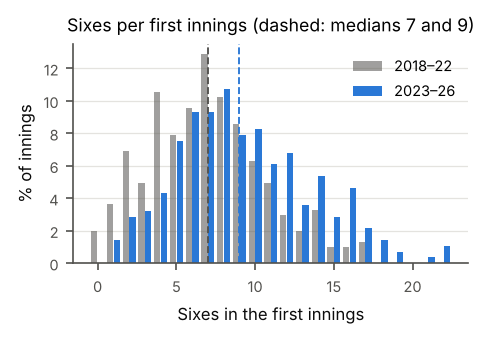

In [18]:
# Figure 6: distribution of sixes per first innings, Pre vs Impact
fig, ax = plt.subplots(figsize=(3.4, 1.9))
ks = np.arange(0, 23)
sp = pd.Series(y2).value_counts(normalize=True).reindex(ks, fill_value=0) * 100
si = pd.Series(x2).value_counts(normalize=True).reindex(ks, fill_value=0) * 100
ax.bar(ks - 0.21, sp.values, width=0.4, color=INK2, alpha=0.55, label="2018–22")
ax.bar(ks + 0.21, si.values, width=0.4, color=SERIES[0], label="2023–26")
ax.axvline(np.median(y2), color=INK2, lw=0.9, ls="--"); ax.axvline(np.median(x2), color=SERIES[0], lw=0.9, ls="--")
ax.set_xlabel("Sixes in the first innings"); ax.set_ylabel("% of innings"); ax.legend(loc="upper right")
ax.set_xticks([0, 5, 10, 15, 20]); ax.grid(axis="x", visible=False)
ax.set_title("Sixes per first innings (dashed: medians 7 and 9)")
save(fig, "fig6_sixes")

**Reading.** Per 120 legal balls the median is still 9 vs 7 (p ≈ 10⁻¹⁰). Negative-binomial rate ratio 1.33 (1.22 to 1.44):
a third more sixes per ball; net of the trend 1.18 (1.06 to 1.30), p = 0.002. Sixes now make 29% of first-innings runs (25% before).

### H3: Does winning the toss help win the match?
H0: P(toss winner wins) ≤ 0.5; H1: > 0.5. α = 0.05, one-sided. **One-proportion z-test** on every match with a result
(ties and no-results excluded). Smallest difference that matters: **5 percentage points** (55%).

In [19]:
dec = m[m["result"].eq("Normal") & m["winner"].notna()].copy()
dec["toss_won_match"] = (dec["toss_winner"] == dec["winner"]).astype(int)
k3, n3 = int(dec["toss_won_match"].sum()), len(dec)
phat3 = k3 / n3
z3 = (phat3 - 0.5) / np.sqrt(0.5 * 0.5 / n3)                 # SE under H0 for the statistic
p3 = stats.norm.sf(z3)                                         # one-sided (right)
se3 = np.sqrt(phat3 * (1 - phat3) / n3)                        # SE from the sample for the interval
ci3_two = (phat3 - 1.96 * se3, phat3 + 1.96 * se3)
bt = stats.binomtest(k3, n3, 0.5, alternative="greater")       # exact binomial: alternative test
chi3 = stats.chisquare([k3, n3 - k3])
by_era3 = dec.groupby("era")["toss_won_match"].agg(["sum", "count", "mean"]).round(3)
by_dec3 = dec.groupby("toss_decision")["toss_won_match"].agg(["sum", "count", "mean"]).round(3)
mde3 = (stats.norm.ppf(0.95) + stats.norm.ppf(0.8)) * 0.5 / np.sqrt(n3)
RESULTS["H3"] = {"n": n3, "k": k3, "share": round(k3 / n3, 3), "p": float(p3),
                 "CI_95": [round(float(ci3_two[0]), 3), round(float(ci3_two[1]), 3)],
                 "z": round(float(z3), 2), "p_exact_binomial": float(bt.pvalue), "chi2": round(float(chi3.statistic), 2), "p_chi2_two_sided": float(chi3.pvalue),
                 "by_era": by_era3.to_dict(orient="index"), "by_decision": by_dec3.to_dict(orient="index"),
                 "MDE_80pct_power_pp": round(float(mde3 * 100), 1)}
for k, v in RESULTS["H3"].items(): print(f"{k:>20}: {v}")

                   n: 1218
                   k: 628
               share: 0.516
                   p: 0.1381144993103653
               CI_95: [0.488, 0.544]
                   z: 1.09
    p_exact_binomial: 0.14453017852294112
                chi2: 1.19
    p_chi2_two_sided: 0.2762289986207285
              by_era: {'Early': {'sum': 322, 'count': 626, 'mean': 0.514}, 'Impact': {'sum': 145, 'count': 286, 'mean': 0.507}, 'Pre': {'sum': 161, 'count': 306, 'mean': 0.526}}
         by_decision: {'bat': {'sum': 185, 'count': 408, 'mean': 0.453}, 'field': {'sum': 443, 'count': 810, 'mean': 0.547}}
  MDE_80pct_power_pp: 3.6


**b) Other tests.** One binary outcome per match against a fixed 50%, and np = n(1−p) = 609 ≥ 10, so the normal
approximation holds → one-proportion z-test. Exact binomial test: exact at any n but unnecessary here; p = 0.14, same decision.
Chi-square goodness-of-fit: equivalent (χ² = z² = 1.19) but two-sided only.

**c) Result.** Toss winners won **628 of 1,218 (51.6%)**, 95% CI 48.8% to 54.4%, z = 1.09, p = 0.14: **fail to reject H0**. The CI
upper bound is below 55%, so the data **rule out** the 5 pp edge we said would matter (power to detect it ≈ 97%; MDE at 80% power 3.6 pp).
What matters is the choice, not the coin: toss winners who chose to field won 54.7%, those who batted 45.3%.

**H3, deeper.** Failing to reject is not proof of no effect, so we run an **equivalence test (TOST)** against the ±5 pp
margin: two one-sided z-tests, H0: p ≥ 0.55 and H0: p ≤ 0.45. Rejecting both shows the toss effect lies inside
the margin. A logistic regression then separates the coin (who wins it) from the decision (bat or field).

In [20]:
tost_hi = stats.norm.cdf((phat3 - 0.55) / np.sqrt(0.55 * 0.45 / n3))     # H0: p >= 0.55
tost_lo = stats.norm.sf((phat3 - 0.45) / np.sqrt(0.45 * 0.55 / n3))      # H0: p <= 0.45
l3 = smf.logit("toss_won_match ~ C(toss_decision) + C(era)", dec).fit(disp=0)
p_fd, p_bd = by_dec3.loc["field", "mean"], by_dec3.loc["bat", "mean"]
_, _, z_dec, ci_dec = two_prop(by_dec3.loc["field", "sum"], by_dec3.loc["field", "count"], by_dec3.loc["bat", "sum"], by_dec3.loc["bat", "count"])
RESULTS["H3"]["TOST_p_upper"] = float(tost_hi); RESULTS["H3"]["TOST_p_lower"] = float(tost_lo)
RESULTS["H3"]["TOST_p"] = float(max(tost_hi, tost_lo))
RESULTS["H3"]["field_vs_bat_pp"] = round(float((p_fd - p_bd) * 100), 1)
RESULTS["H3"]["field_vs_bat_CI"] = [round(float(ci_dec[0] * 100), 1), round(float(ci_dec[1] * 100), 1)]
RESULTS["H3"]["field_OR"] = round(float(np.exp(l3.params["C(toss_decision)[T.field]"])), 2)
RESULTS["H3"]["field_OR_CI"] = [round(float(v), 2) for v in np.exp(l3.conf_int().loc["C(toss_decision)[T.field]"])]
RESULTS["H3"]["field_p"] = float(l3.pvalues["C(toss_decision)[T.field]"])
RESULTS["H3"]["era_decision"] = dec.groupby(["era", "toss_decision"])["toss_won_match"].agg(["mean", "count"]).round(3).reset_index().to_dict(orient="records")
print({k: RESULTS["H3"][k] for k in ["TOST_p", "field_vs_bat_pp", "field_vs_bat_CI", "field_OR", "field_OR_CI", "field_p"]})

{'TOST_p': 0.007905429502688034, 'field_vs_bat_pp': 9.4, 'field_vs_bat_CI': [3.4, 15.3], 'field_OR': 1.48, 'field_OR_CI': [1.16, 1.89], 'field_p': 0.0017376906737040813}


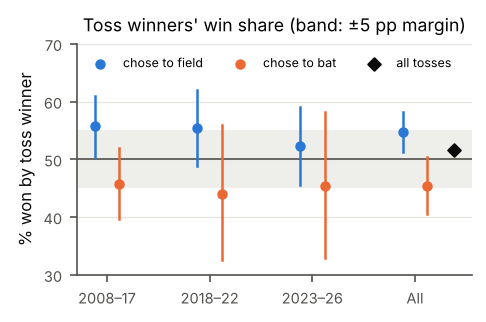

In [21]:
# Figure 7: toss-winner win share by era and decision, with 95% exact CIs and the ±5 pp equivalence band
fig, ax = plt.subplots(figsize=(3.4, 2.0))
ax.axhspan(45, 55, color=GRID, alpha=0.6, lw=0); ax.axhline(50, color=INK2, lw=0.8)
cells = [("Early", "2008–17"), ("Pre", "2018–22"), ("Impact", "2023–26"), ("All", "All")]
for j, (dname, colr, off) in enumerate([("field", SERIES[0], -0.12), ("bat", SERIES[1], 0.12)]):
    for i, (e, lab) in enumerate(cells):
        g = dec[dec["toss_decision"] == dname] if e == "All" else dec[(dec["era"] == e) & (dec["toss_decision"] == dname)]
        kk, nn = int(g["toss_won_match"].sum()), len(g); ci = stats.binomtest(kk, nn).proportion_ci(method="exact")
        ax.plot([i + off] * 2, [ci.low * 100, ci.high * 100], color=colr, lw=1.2)
        ax.scatter(i + off, kk / nn * 100, color=colr, s=16, zorder=3, label=("chose to " + dname) if i == 0 else None)
ax.scatter(3.38, k3 / n3 * 100, color=INK, s=18, marker="D", zorder=3, label="all tosses")
ax.set_xticks(range(4)); ax.set_xticklabels([c[1] for c in cells]); ax.grid(axis="x", visible=False)
ax.set_ylabel("% won by toss winner"); ax.set_ylim(30, 70); ax.legend(loc="upper left", ncol=3, fontsize=6)
ax.set_title("Toss winners' win share (band: ±5 pp margin)")
save(fig, "fig7_toss")

**Reading.** TOST rejects both p ≥ 0.55 (p = 0.008) and p ≤ 0.45 (p < 10⁻⁵): the toss effect is **equivalent to zero
within ±5 pp**. The decision matters: fielding first wins 9.4 pp more often than batting first (3.4 to 15.3), odds ratio 1.48.

### H4: Has the chasing team's win share changed across eras?
H0: the chasing side's win share is equal in all three eras (2008–17, 2018–22, 2023–26); H1: it differs in at least one.
α = 0.05. **Chi-square test of independence (3×2)**, with Cramér's V. Smallest difference that matters: **10 pp** between any two eras.

In [22]:
clean["chase_won"] = (clean["winner"] == clean["batting_second"]).astype(int)
ct4 = pd.crosstab(clean["era"], clean["chase_won"]).reindex(["Early", "Pre", "Impact"])
chi4, p4, dof4, exp4 = stats.chi2_contingency(ct4.values, correction=False)
n4 = ct4.values.sum(); cv4 = np.sqrt(chi4 / (n4 * (min(ct4.shape) - 1)))
g4 = stats.chi2_contingency(ct4.values, correction=False, lambda_="log-likelihood")
share4 = (ct4[1] / ct4.sum(axis=1))
pairs, praw, cis = [], [], []
for a, c in [("Early", "Pre"), ("Pre", "Impact"), ("Early", "Impact")]:
    p1, p2, z, ci = two_prop(ct4.loc[c, 1], ct4.loc[c].sum(), ct4.loc[a, 1], ct4.loc[a].sum())
    pairs.append(f"{c} − {a}"); praw.append(2 * stats.norm.sf(abs(z))); cis.append((round(float(p1 - p2) * 100, 1), round(float(ci[0]) * 100, 1), round(float(ci[1]) * 100, 1)))
pholm = multipletests(praw, method="holm")[1]
logit4 = sm.Logit(clean["chase_won"], sm.add_constant(pd.get_dummies(clean["era"], dtype=float)[["Pre", "Impact"]])).fit(disp=0)
RESULTS["H4"] = {"table": ct4.to_dict(), "n_by_era": ct4.sum(axis=1).to_dict(), "chase_share": share4.round(3).to_dict(),
                 "chi2": round(float(chi4), 2), "df": int(dof4), "p": float(p4), "cramers_v": round(float(cv4), 3),
                 "G": round(float(g4[0]), 2), "p_G": float(g4[1]), "min_expected": round(float(exp4.min()), 1),
                 "pairwise": {pp: {"diff_pp": c[0], "CI_pp": [c[1], c[2]], "p_raw": float(r), "p_holm": float(h)}
                              for pp, c, r, h in zip(pairs, cis, praw, pholm)},
                 "logit_LR_p": float(logit4.llr_pvalue), "overall_chase_share": round(float(clean["chase_won"].mean()), 3)}
for k, v in RESULTS["H4"].items(): print(f"{k:>18}: {v}")

             table: {0: {'Early': 274, 'Pre': 134, 'Impact': 131}, 1: {'Early': 327, 'Pre': 169, 'Impact': 148}}
          n_by_era: {'Early': 601, 'Pre': 303, 'Impact': 279}
       chase_share: {'Early': 0.544, 'Pre': 0.558, 'Impact': 0.53}
              chi2: 0.44
                df: 2
                 p: 0.8039100438364469
         cramers_v: 0.019
                 G: 0.44
               p_G: 0.8038924336765302
      min_expected: 127.1
          pairwise: {'Pre − Early': {'diff_pp': 1.4, 'CI_pp': [-5.5, 8.2], 'p_raw': 0.6967751750410194, 'p_holm': 1.0}, 'Impact − Pre': {'diff_pp': -2.7, 'CI_pp': [-10.8, 5.4], 'p_raw': 0.5089717695621789, 'p_holm': 1.0}, 'Impact − Early': {'diff_pp': -1.4, 'CI_pp': [-8.4, 5.7], 'p_raw': 0.7058686244924443, 'p_holm': 1.0}}
        logit_LR_p: 0.8038924002116778
overall_chase_share: 0.544


**b) Other tests.** Two categorical variables (era with 3 levels × chase won), all expected counts ≥ 127 → chi-square test of
independence. Pairwise two-proportion z-tests: three tests need a Holm correction and still do not answer "any difference".
Fisher's exact: built for small 2×2 tables. G-test: same answer (G = 0.44). Logistic regression on era: likelihood-ratio p = 0.80.

**c) Result.** Chasing sides won **54.4%, 55.8% and 53.0%** in 2008–17, 2018–22 and 2023–26; χ² = 0.44 (2 d.f.), p = 0.80,
Cramér's V = 0.02: **fail to reject H0**. Chasing has a steady ~54% edge. Impact − Pre = −2.7 pp (−10.8 to +5.4), so a
10 pp fall is not fully ruled out, but a rise is. Higher totals have not made chasing easier or harder.

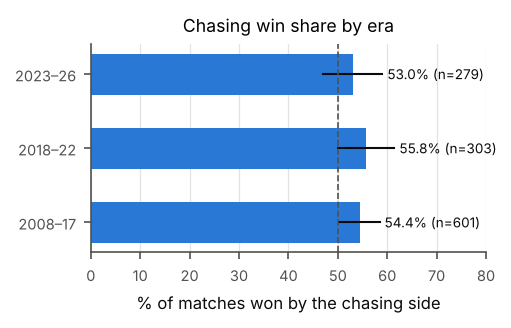

In [23]:
# Figure 3: chasing win share by era with 95% CI
fig, ax = plt.subplots(figsize=(3.4, 1.8))
eras = ["Early", "Pre", "Impact"]; labels = ["2008–17", "2018–22", "2023–26"]
for i, e in enumerate(eras):
    k, n = ct4.loc[e, 1], ct4.loc[e].sum(); ci = stats.binomtest(int(k), int(n)).proportion_ci(method="exact")
    ax.barh(i, k / n * 100, color=SERIES[0], height=0.55)
    ax.plot([ci.low * 100, ci.high * 100], [i, i], color=INK, lw=1)
    ax.text(ci.high * 100 + 1, i, f"{k / n * 100:.1f}% (n={n})", va="center", fontsize=6.5, color=INK)
ax.axvline(50, color=INK2, lw=0.8, ls="--")
ax.set_yticks(range(3)); ax.set_yticklabels(labels); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 80); ax.set_xlabel("% of matches won by the chasing side"); ax.set_title("Chasing win share by era")
save(fig, "fig3_chase")

**H4, deeper: why has the chase share not moved?** Impact-era targets are ~22 runs higher. A logistic regression of
`chase_won ~ target + era` asks whether, at the *same* target, chasing sides now win more often; an era × target
interaction asks whether the slope changed.

In [24]:
clean["target"] = clean["first_innings_runs"] + 1
l4 = smf.logit('chase_won ~ target + C(era, Treatment("Pre"))', clean).fit(disp=0)
l4i = smf.logit('chase_won ~ target * C(era, Treatment("Pre"))', clean).fit(disp=0)
lr_int = 2 * (l4i.llf - l4.llf)
key_i = 'C(era, Treatment("Pre"))[T.Impact]'; key_e = 'C(era, Treatment("Pre"))[T.Early]'
RESULTS["H4"]["target_by_era"] = clean.groupby("era")["target"].mean().round(1).to_dict()
RESULTS["H4"]["OR_per10runs"] = round(float(np.exp(10 * l4.params["target"])), 2)
RESULTS["H4"]["OR_per10runs_CI"] = [round(float(v), 2) for v in np.exp(10 * l4.conf_int().loc["target"])]
RESULTS["H4"]["OR_impact_same_target"] = round(float(np.exp(l4.params[key_i])), 2)
RESULTS["H4"]["OR_impact_CI"] = [round(float(v), 2) for v in np.exp(l4.conf_int().loc[key_i])]
RESULTS["H4"]["OR_impact_p"] = float(l4.pvalues[key_i])
RESULTS["H4"]["OR_early_same_target"] = round(float(np.exp(l4.params[key_e])), 2)
RESULTS["H4"]["OR_early_p"] = float(l4.pvalues[key_e])
RESULTS["H4"]["interaction_LR"] = round(float(lr_int), 2); RESULTS["H4"]["interaction_p"] = float(stats.chi2.sf(lr_int, 2))
p180 = {e: float(l4.predict(pd.DataFrame({"target": [181], "era": [e]}))[0]) for e in ["Pre", "Impact"]}
RESULTS["H4"]["p_win_chasing_181"] = {k: round(v, 3) for k, v in p180.items()}
print({k: RESULTS["H4"][k] for k in ["target_by_era", "OR_per10runs", "OR_impact_same_target", "OR_impact_CI", "OR_impact_p", "interaction_p", "p_win_chasing_181"]})

{'target_by_era': {'Early': 162.0, 'Impact': 191.4, 'Pre': 169.1}, 'OR_per10runs': 0.7, 'OR_impact_same_target': 1.97, 'OR_impact_CI': [1.34, 2.89], 'OR_impact_p': 0.0005820287380764591, 'interaction_p': 0.47891947329841356, 'p_win_chasing_181': {'Pre': 0.467, 'Impact': 0.633}}


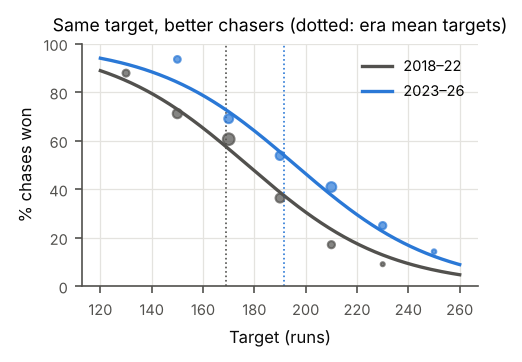

In [25]:
# Figure 8: chance of a successful chase against the target, Pre vs Impact (model curves, binned observed shares)
fig, ax = plt.subplots(figsize=(3.4, 2.1))
grid = np.arange(120, 261)
for e, colr, lab in [("Pre", INK2, "2018–22"), ("Impact", SERIES[0], "2023–26")]:
    pr = l4.predict(pd.DataFrame({"target": grid, "era": e}))
    ax.plot(grid, pr * 100, color=colr, label=lab)
    g = clean[clean["era"] == e].assign(bin=lambda d: (d["target"] // 20) * 20 + 10)
    bb = g.groupby("bin")["chase_won"].agg(["mean", "count"]); bb = bb[bb["count"] >= 10]
    ax.scatter(bb.index, bb["mean"] * 100, color=colr, s=bb["count"] / 3, alpha=0.7, zorder=3)
    ax.axvline(clean[clean["era"] == e]["target"].mean(), color=colr, lw=0.8, ls=":")
ax.set_xlabel("Target (runs)"); ax.set_ylabel("% chases won"); ax.set_ylim(0, 100); ax.legend(loc="upper right")
ax.set_title("Same target, better chasers (dotted: era mean targets)")
save(fig, "fig8_chase_target")

**Reading.** Each extra 10 runs of target cuts the odds of a successful chase by 30% (OR 0.70). At the *same* target,
Impact-era chasers have about twice the odds (OR 1.97, 1.34 to 2.89, p < 0.001): chasing 181 succeeds 63% of the time now vs
47% before. Higher targets and better chasing cancel out, which is why the overall share in H4 has not moved.

### H5: Does a powerplay collapse sink the batting-first team?
Collapse = 3+ wickets in overs 1–6 of the first innings (one observation per match). H0: p_win,collapse − p_win,no ≥ 0;
H1: < 0. α = 0.05, one-sided. **Two-proportion z-test.** Smallest difference that matters: **15 pp**.

In [26]:
first["collapse"] = (first["pp_wkts"] >= 3).astype(int)
t5 = first.groupby("collapse")["bf_won"].agg(["sum", "count"])
pC, pN, z5, ci5 = two_prop(t5.loc[1, "sum"], t5.loc[1, "count"], t5.loc[0, "sum"], t5.loc[0, "count"])
p5 = stats.norm.cdf(z5)
ct5 = np.array([[t5.loc[1, "sum"], t5.loc[1, "count"] - t5.loc[1, "sum"]], [t5.loc[0, "sum"], t5.loc[0, "count"] - t5.loc[0, "sum"]]])
chi5 = stats.chi2_contingency(ct5, correction=False)
fis5 = stats.fisher_exact(ct5, alternative="less")
lg5 = sm.Logit(first["bf_won"], sm.add_constant(first[["pp_wkts"]].astype(float))).fit(disp=0)
or_per_wkt = float(np.exp(lg5.params["pp_wkts"])); or_ci = np.exp(lg5.conf_int().loc["pp_wkts"]).values
by_w = first.assign(w=first["pp_wkts"].clip(upper=5)).groupby("w")["bf_won"].agg(["mean", "count"])
# Same question for the chasing side (second innings), as an extension
sec = inn[(inn["innings"] == 2) & inn["match_id"].isin(clean["match_id"])].copy()
sec["won"] = (sec["winner"] != sec["batting_first"]).astype(int); sec["collapse"] = (sec["pp_wkts"] >= 3).astype(int)
t5s = sec.groupby("collapse")["won"].agg(["sum", "count"])
pCs, pNs, z5s, ci5s = two_prop(t5s.loc[1, "sum"], t5s.loc[1, "count"], t5s.loc[0, "sum"], t5s.loc[0, "count"])
RESULTS["H5"] = {"n_collapse": int(t5.loc[1, "count"]), "n_no": int(t5.loc[0, "count"]),
                 "win_collapse": round(float(pC), 3), "win_no": round(float(pN), 3), "diff_pp": round(float((pC - pN) * 100), 1),
                 "CI_pp": [round(float(ci5[0] * 100), 1), round(float(ci5[1] * 100), 1)], "z": round(float(z5), 2), "p": float(p5),
                 "chi2": round(float(chi5[0]), 2), "p_chi2": float(chi5[1]), "fisher_OR": round(float(fis5.statistic), 2), "p_fisher": float(fis5.pvalue),
                 "logit_OR_per_wkt": round(or_per_wkt, 2), "logit_OR_CI": [round(float(or_ci[0]), 2), round(float(or_ci[1]), 2)],
                 "logit_p": float(lg5.pvalues["pp_wkts"]), "win_by_pp_wkts": by_w.round(3).to_dict(orient="index"),
                 "chase_ext": {"win_collapse": round(float(pCs), 3), "win_no": round(float(pNs), 3), "diff_pp": round(float((pCs - pNs) * 100), 1),
                               "CI_pp": [round(float(ci5s[0] * 100), 1), round(float(ci5s[1] * 100), 1)], "z": round(float(z5s), 2),
                               "n_collapse": int(t5s.loc[1, "count"])}}
for k, v in RESULTS["H5"].items(): print(f"{k:>16}: {v}")

      n_collapse: 174
            n_no: 1009
    win_collapse: 0.236
          win_no: 0.494
         diff_pp: -25.8
           CI_pp: [-32.8, -18.8]
               z: -6.31
               p: 1.402967504523103e-10
            chi2: 39.81
          p_chi2: 2.8059350090462063e-10
       fisher_OR: 0.32
        p_fisher: 8.221237991995688e-11
logit_OR_per_wkt: 0.63
     logit_OR_CI: [0.56, 0.7]
         logit_p: 5.495656292917023e-15
  win_by_pp_wkts: {0: {'mean': 0.606, 'count': 259}, 1: {'mean': 0.491, 'count': 446}, 2: {'mean': 0.401, 'count': 304}, 3: {'mean': 0.264, 'count': 129}, 4: {'mean': 0.158, 'count': 38}, 5: {'mean': 0.143, 'count': 7}}
       chase_ext: {'win_collapse': 0.251, 'win_no': 0.611, 'diff_pp': -36.0, 'CI_pp': [-42.5, -29.5], 'z': -9.65, 'n_collapse': 219}


**b) Other tests.** Two independent groups, binary outcome, large counts → two-proportion z-test (one-sided). Chi-square: same
test squared, two-sided only (χ² = 39.8). Fisher's exact: not needed at n = 1,183 (OR 0.32, p ≈ 8×10⁻¹¹). Logistic regression on
the number of powerplay wickets: uses the full count instead of a 3+ cut-off; each wicket multiplies the odds of winning by 0.63.

**c) Result.** Batting-first teams that lost 3+ powerplay wickets won **23.6%** of matches vs **49.4%** otherwise:
**−25.8 pp** (95% CI −32.8 to −18.8; z = −6.31, p ≈ 1.4×10⁻¹⁰). Reject H0; the whole CI is beyond −15 pp, so it **matters**.
Chasing sides show the same pattern (25.1% vs 61.1%).

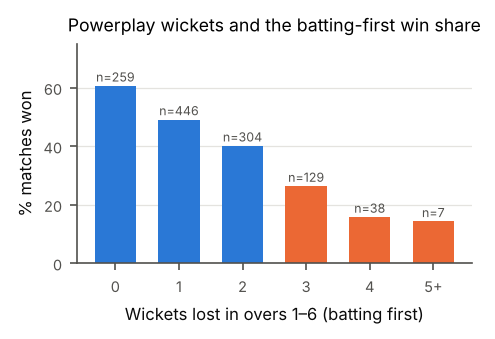

In [27]:
# Figure 4: batting-first win share by powerplay wickets lost
fig, ax = plt.subplots(figsize=(3.4, 1.9))
xs = by_w.index.values; ys = by_w["mean"].values * 100
cols = [SERIES[1] if w >= 3 else SERIES[0] for w in xs]
ax.bar(xs, ys, color=cols, width=0.65)
for xv, yv, n in zip(xs, ys, by_w["count"].values):
    ax.text(xv, yv + 1.5, f"n={n}", ha="center", fontsize=6, color=INK2)
ax.set_xticks(xs); ax.set_xticklabels([str(int(v)) if v < 5 else "5+" for v in xs]); ax.grid(axis="x", visible=False)
ax.set_xlabel("Wickets lost in overs 1–6 (batting first)"); ax.set_ylabel("% matches won"); ax.set_ylim(0, 75)
ax.set_title("Powerplay wickets and the batting-first win share")
save(fig, "fig4_powerplay")

**H5, deeper.** (i) Does the penalty survive adjustment for venue and the season trend? (ii) Does the Impact Player rule,
which lets a side bat deeper, *soften* the penalty? We add a powerplay-wickets × Impact interaction.

In [28]:
l5a = smf.logit("bf_won ~ pp_wkts + t + C(venue)", first).fit(disp=0)
l5i = smf.logit("bf_won ~ pp_wkts * impact", first).fit(disp=0)
coll_era = first.assign(c=(first["pp_wkts"] >= 3).astype(int)).groupby(["impact", "c"])["bf_won"].agg(["mean", "count"])
tot_by_w = first.assign(w=first["pp_wkts"].clip(upper=5)).groupby("w")["runs"].mean().round(1)
RESULTS["H5"]["adj_OR_per_wkt"] = round(float(np.exp(l5a.params["pp_wkts"])), 2)
RESULTS["H5"]["adj_OR_CI"] = [round(float(v), 2) for v in np.exp(l5a.conf_int().loc["pp_wkts"])]
RESULTS["H5"]["adj_p"] = float(l5a.pvalues["pp_wkts"])
RESULTS["H5"]["interaction_OR"] = round(float(np.exp(l5i.params["pp_wkts:impact"])), 2)
RESULTS["H5"]["interaction_CI"] = [round(float(v), 2) for v in np.exp(l5i.conf_int().loc["pp_wkts:impact"])]
RESULTS["H5"]["interaction_p"] = float(l5i.pvalues["pp_wkts:impact"])
RESULTS["H5"]["collapse_by_era"] = {f"impact={a},collapse={b}": {"win": round(float(r["mean"]), 3), "n": int(r["count"])} for (a, b), r in coll_era.iterrows()}
RESULTS["H5"]["total_by_pp_wkts"] = tot_by_w.to_dict()
print({k: RESULTS["H5"][k] for k in ["adj_OR_per_wkt", "adj_OR_CI", "interaction_OR", "interaction_CI", "interaction_p", "collapse_by_era"]})

{'adj_OR_per_wkt': 0.61, 'adj_OR_CI': [0.54, 0.69], 'interaction_OR': 1.07, 'interaction_CI': [0.82, 1.39], 'interaction_p': 0.6236807996166895, 'collapse_by_era': {'impact=0,collapse=0': {'win': 0.49, 'n': 780}, 'impact=0,collapse=1': {'win': 0.21, 'n': 124}, 'impact=1,collapse=0': {'win': 0.507, 'n': 229}, 'impact=1,collapse=1': {'win': 0.3, 'n': 50}}}


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


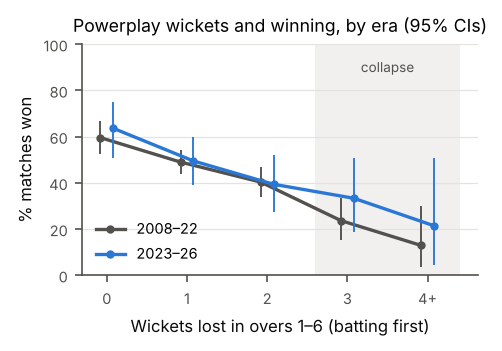

In [29]:
# Figure 9: batting-first win share by powerplay wickets, before vs during the Impact era
fig, ax = plt.subplots(figsize=(3.4, 2.0))
for e, colr, lab, off in [(0, INK2, "2008–22", -0.08), (1, SERIES[0], "2023–26", 0.08)]:
    g = first[first["impact"] == e].assign(w=lambda d: d["pp_wkts"].clip(upper=4)).groupby("w")["bf_won"].agg(["sum", "count"])
    lo = [stats.binomtest(int(a), int(b)).proportion_ci(method="exact").low * 100 for a, b in zip(g["sum"], g["count"])]
    hi = [stats.binomtest(int(a), int(b)).proportion_ci(method="exact").high * 100 for a, b in zip(g["sum"], g["count"])]
    mu = (g["sum"] / g["count"] * 100).values
    ax.plot(g.index + off, mu, color=colr, marker="o", ms=3, label=lab)
    ax.vlines(g.index + off, lo, hi, color=colr, lw=0.9)
ax.axvspan(2.6, 4.4, color=GRID, alpha=0.5, lw=0); ax.text(3.5, 88, "collapse", ha="center", fontsize=6.5, color=INK2)
ax.set_xticks(range(5)); ax.set_xticklabels(["0", "1", "2", "3", "4+"]); ax.grid(axis="x", visible=False)
ax.set_xlabel("Wickets lost in overs 1–6 (batting first)"); ax.set_ylabel("% matches won"); ax.set_ylim(0, 100)
ax.legend(loc="lower left"); ax.set_title("Powerplay wickets and winning, by era (95% CIs)")
save(fig, "fig9_powerplay_era")

**Reading.** Adjusted for venue and trend, each powerplay wicket still multiplies the odds of winning by 0.61 (0.54 to 0.69).
The Impact-era interaction is OR 1.07 (0.82 to 1.39, p = 0.62): no evidence that batting deeper softens a collapse.

In [30]:
# Links between the tests: the same evidence in different forms
anova1 = stats.f_oneway(imp["runs"], pre["runs"])
RESULTS["links"] = {
    "H1_pooled_t_sq": round(RESULTS["H1"]["pooled_t"] ** 2, 1), "H1_anova_F": round(float(anova1.statistic), 1), "H1_anova_p": float(anova1.pvalue),
    "H3_z_sq": round(RESULTS["H3"]["z"] ** 2, 2), "H3_chi2_gof": RESULTS["H3"]["chi2"],
    "H5_z_sq": round(RESULTS["H5"]["z"] ** 2, 1), "H5_chi2": RESULTS["H5"]["chi2"],
    "H4_chi2": RESULTS["H4"]["chi2"], "H4_G": RESULTS["H4"]["G"],
}
print(RESULTS["links"])

{'H1_pooled_t_sq': 66.9, 'H1_anova_F': 67.0, 'H1_anova_p': 1.7444554176310838e-15, 'H3_z_sq': 1.19, 'H3_chi2_gof': 1.19, 'H5_z_sq': 39.8, 'H5_chi2': 39.81, 'H4_chi2': 0.44, 'H4_G': 0.44}


In [31]:
# Robustness across the five tests: Holm adjustment of the five primary p-values
prim = {"H1": RESULTS["H1"]["p"], "H2": RESULTS["H2"]["p"], "H3": RESULTS["H3"]["p"], "H4": RESULTS["H4"]["p"], "H5": RESULTS["H5"]["p"]}
RESULTS["holm_five"] = dict(zip(prim, [float(v) for v in multipletests(list(prim.values()), method="holm")[1]]))
print(RESULTS["holm_five"])

{'H1': 7.559563899443456e-15, 'H2': 5.3179806828623553e-11, 'H3': 0.2762289986207306, 'H4': 0.8039100438364469, 'H5': 4.2089025135693087e-10}


### Summary: main result and the strongest robustness check for each test
The five hypotheses, their sides and thresholds were fixed before any outcome in the data was examined; the checks
below were added afterwards to probe the obvious alternative explanations.

In [32]:
summary = pd.DataFrame([
    ["H1 totals", f"+{RESULTS['H1']['diff']} runs ({RESULTS['H1']['CI'][0]}, {RESULTS['H1']['CI'][1]})", RESULTS["holm_five"]["H1"],
     f"+{RESULTS['H1']['trend_jump']} runs beyond the trend ({RESULTS['H1']['trend_jump_CI'][0]}, {RESULTS['H1']['trend_jump_CI'][1]}); placebo years ≤ {RESULTS['H1']['placebo_max_abs']}", "reject"],
    ["H2 sixes", f"+{RESULTS['H2']['mean_diff']} sixes ({RESULTS['H2']['mean_diff_CI'][0]}, {RESULTS['H2']['mean_diff_CI'][1]})", RESULTS["holm_five"]["H2"],
     f"rate ratio {RESULTS['H2']['NB_trend_IRR']} per ball net of trend ({RESULTS['H2']['NB_trend_IRR_CI'][0]}, {RESULTS['H2']['NB_trend_IRR_CI'][1]})", "reject"],
    ["H3 toss", f"{RESULTS['H3']['share']*100:.1f}% ({RESULTS['H3']['CI_95'][0]*100:.1f}, {RESULTS['H3']['CI_95'][1]*100:.1f})", RESULTS["holm_five"]["H3"],
     f"TOST: equivalent to 50% within ±5 pp (p = {RESULTS['H3']['TOST_p']:.3f})", "fail to reject"],
    ["H4 chase", "54.4 / 55.8 / 53.0%", RESULTS["holm_five"]["H4"],
     f"same target: Impact-era chasers OR {RESULTS['H4']['OR_impact_same_target']} ({RESULTS['H4']['OR_impact_CI'][0]}, {RESULTS['H4']['OR_impact_CI'][1]})", "fail to reject"],
    ["H5 collapse", f"{RESULTS['H5']['diff_pp']} pp ({RESULTS['H5']['CI_pp'][0]}, {RESULTS['H5']['CI_pp'][1]})", RESULTS["holm_five"]["H5"],
     f"OR {RESULTS['H5']['adj_OR_per_wkt']} per wicket, venue + trend adjusted; era interaction p = {RESULTS['H5']['interaction_p']:.2f}", "reject"],
], columns=["test", "main estimate (95% CI)", "Holm p", "strongest robustness check", "decision"])
RESULTS["summary"] = summary.to_dict(orient="records")
summary

,test,main estimate (95% CI),Holm p,strongest robustness check,decision
0,H1 totals,"+22.3 runs (16.9, 27.7)",7.559564e-15,"+18.1 runs beyond the trend (11.9, 24.3); plac...",reject
1,H2 sixes,"+2.29 sixes (1.63, 2.95)",5.317981e-11,"rate ratio 1.18 per ball net of trend (1.06, 1.3)",reject
2,H3 toss,"51.6% (48.8, 54.4)",2.762290e-01,TOST: equivalent to 50% within ±5 pp (p = 0.008),fail to reject
3,H4 chase,54.4 / 55.8 / 53.0%,8.039100e-01,"same target: Impact-era chasers OR 1.97 (1.34,...",fail to reject
4,H5 collapse,"-25.8 pp (-32.8, -18.8)",4.208903e-10,"OR 0.61 per wicket, venue + trend adjusted; er...",reject


## Limitations
* **Before/after, not a controlled experiment.** The Impact era also brought the two-bouncer rule (2024), new venues
  and squads; H1–H2 measure the era, not the rule alone.
* **Venue mix.** 2020 and part of 2021 were played in the UAE; the India-only sensitivity check addresses this.
* **Matches left out.** No-results, ties, D/L and other shortened games are excluded from score and chase tests.
* **One league, 19 seasons.** Conclusions apply to the IPL, not T20 cricket in general.

## 6. Export

In [33]:
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    return o
(OUT_DIR / "results.json").write_text(json.dumps(to_py(RESULTS), indent=2, default=str))
prep_table.to_csv(OUT_DIR / "prep_table.csv", index=False)
before_after.to_csv(OUT_DIR / "before_after.csv")
first.to_csv(OUT_DIR / "first_innings_clean.csv", index=False)
print("Saved:", sorted(p.name for p in OUT_DIR.iterdir()))

Saved: ['before_after.csv', 'first_innings_clean.csv', 'prep_table.csv', 'results.json']
